<a href="https://colab.research.google.com/github/aliluqmanul/tubesLomba_visdat/blob/main/Nama_Tim_nya_mau_apaaa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Pipeline & Validation Lead


In [61]:
import os, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import lightgbm as lgb
from scipy.stats import rankdata
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

In [62]:

warnings.filterwarnings('ignore')
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print('Di Colab:', IN_COLAB, '| LightGBM', lgb.__version__)

Di Colab: False | LightGBM 4.7.0


In [63]:
PAKAI_DRIVE = False  # ubah ke False kalau tidak mau pakai Google Drive

if IN_COLAB and PAKAI_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/ps-s6e11')
elif IN_COLAB:
    ROOT = Path('/content/ps-s6e11')
else:
    ROOT = Path(os.environ.get('PS_ROOT', 'ps-s6e11'))

DATA_DIR = ROOT / 'data'
OOF_DIR  = ROOT / 'oof'
SUB_DIR  = ROOT / 'submissions'
for d in (DATA_DIR, OOF_DIR, SUB_DIR):
    d.mkdir(parents=True, exist_ok=True)
print('Folder kerja:', ROOT)

Folder kerja: ps-s6e11


In [64]:
import shutil, glob

need = ['train.csv', 'test.csv', 'sample_submission.csv']

for f in need:
    target = DATA_DIR / f
    if target.exists():
        continue
    # cari file di /content (termasuk nama berawalan aneh, mis. '3b4bf4ca-sample_submission.csv')
    found = sorted(glob.glob(f'/content/*{f}')) + sorted(glob.glob(f'/content/**/*{f}', recursive=True))
    found = [p for p in found if not p.startswith(str(DATA_DIR))]
    if found:
        shutil.copy(found[0], target)
        print(f'{f} <- {found[0]}')
    else:
        print(f'TIDAK KETEMU: {f}')

print('Isi folder data:', sorted(os.listdir(DATA_DIR)))

Isi folder data: ['folds.csv', 'sample_submission.csv', 'test.csv', 'train.csv']


In [65]:
ID, TARGET = 'id', 'is_fraud'
N_FOLDS, SEED = 5, 42     # JANGAN diubah tanpa diskusi tim

CAT_COLS  = ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']
BOOL_COLS = ['is_foreign_transaction', 'is_new_merchant', 'used_vpn',
             'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']

train  = pd.read_csv(DATA_DIR / 'train.csv')
test   = pd.read_csv(DATA_DIR / 'test.csv')
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')

print('train :', train.shape)
print('test  :', test.shape)
print('sample:', sample.shape)
print(f'Proporsi fraud: {train[TARGET].mean():.4%}')
print('Missing value train:', int(train.isna().sum().sum()), '| test:', int(test.isna().sum().sum()))
train.head()

train : (699960, 26)
test  : (299984, 25)
sample: (299984, 2)
Proporsi fraud: 1.6700%
Missing value train: 0 | test: 0


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [66]:
FOLDS_PATH = DATA_DIR / 'folds.csv'

if not FOLDS_PATH.exists():
    folds = train[[ID]].copy()
    folds['fold'] = -1
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    for k, (_, va_idx) in enumerate(skf.split(train, train[TARGET])):
        folds.loc[va_idx, 'fold'] = k
    folds.to_csv(FOLDS_PATH, index=False)
    print('folds.csv dibuat')
else:
    print('folds.csv sudah ada, dipakai ulang')

folds = pd.read_csv(FOLDS_PATH)
train = train.drop(columns='fold', errors='ignore').merge(folds, on=ID, how='left', validate='one_to_one')
assert train['fold'].between(0, N_FOLDS - 1).all()
train.groupby('fold')[TARGET].agg(jumlah='size', fraud_rate='mean')

folds.csv sudah ada, dipakai ulang


,jumlah,fraud_rate
fold,,
0,139992,0.016694
1,139992,0.016701
2,139992,0.016701
3,139992,0.016701
4,139992,0.016701


In [67]:
def preprocess(train, test):
    train, test = train.copy(), test.copy()
    for c in BOOL_COLS:
        for df in (train, test):
            df[c] = df[c].astype(str).str.lower().eq('true').astype('int8')
    for c in CAT_COLS:
        cats = sorted(pd.concat([train[c], test[c]]).astype(str).unique())
        dtype = pd.CategoricalDtype(categories=cats)
        for df in (train, test):
            df[c] = df[c].astype(str).astype(dtype)
    return train, test

train_p, test_p = preprocess(train, test)
FEATS = [c for c in test_p.columns if c != ID]
print(len(FEATS), 'fitur:', FEATS)

24 fitur: ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes', 'merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']


In [68]:
def check_submission(sub):
    assert list(sub.columns) == [ID, TARGET], f'Kolom harus {[ID, TARGET]}'
    assert len(sub) == len(sample), f'Jumlah baris {len(sub)} != {len(sample)}'
    assert (sub[ID].values == sample[ID].values).all(), 'Urutan id beda dengan sample_submission'
    assert sub[TARGET].notna().all(), 'Ada NaN'
    assert sub[TARGET].between(0, 1).all(), 'Prediksi harus 0..1'
    print(f'[OK] Format submission valid ({len(sub)} baris)')


def log_experiment(name, cv, scores):
    log_path = ROOT / 'experiments.csv'
    row = pd.DataFrame([{
        'waktu': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M'),
        'nama': name, 'cv_auc': round(cv, 6),
        'std_fold': round(float(np.std(scores)), 6), 'public_lb': '',
    }])
    log = pd.concat([pd.read_csv(log_path), row]) if log_path.exists() else row
    log.to_csv(log_path, index=False)
    print(f'Tercatat di {log_path.name}')


def run_cv(name, fit_predict, X=None, X_test=None):
    X = train_p if X is None else X
    X_test = test_p if X_test is None else X_test
    feats = [c for c in X_test.columns if c != ID]

    oof = np.zeros(len(X))
    pred = np.zeros(len(X_test))
    scores = []
    for k in range(N_FOLDS):
        t0 = time.time()
        tr = X[X['fold'] != k]
        va = X[X['fold'] == k]
        assert set(tr[ID]).isdisjoint(va[ID])          # cek anti-bocor

        p_va, p_te = fit_predict(tr[feats], tr[TARGET], va[feats], va[TARGET], X_test[feats])
        oof[va.index] = p_va
        pred += p_te / N_FOLDS
        scores.append(roc_auc_score(va[TARGET], p_va))
        print(f'Fold {k}: AUC = {scores[-1]:.5f}  ({time.time() - t0:.0f}s)')

    cv = roc_auc_score(X[TARGET], oof)
    print('-' * 45)
    print(f'Mean fold AUC  : {np.mean(scores):.5f} ± {np.std(scores):.5f}')
    print(f'Overall OOF AUC: {cv:.5f}')

    pd.DataFrame({ID: X[ID], TARGET: oof}).to_csv(OOF_DIR / f'{name}_oof.csv', index=False)
    pd.DataFrame({ID: X_test[ID], TARGET: pred}).to_csv(OOF_DIR / f'{name}_test.csv', index=False)

    sub = sample[[ID]].merge(pd.DataFrame({ID: X_test[ID], TARGET: pred}), on=ID, how='left')
    check_submission(sub)
    sub.to_csv(SUB_DIR / f'{name}.csv', index=False)

    log_experiment(name, cv, scores)
    return oof, pred, cv

In [69]:
LGB_PARAMS = dict(
    objective='binary', learning_rate=0.05, n_estimators=5000,
    num_leaves=31, min_child_samples=50,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    reg_lambda=1.0, random_state=SEED, n_jobs=-1, verbose=-1,
)
importances = []

def lgb_fit_predict(X_tr, y_tr, X_va, y_va, X_te):
    model = lgb.LGBMClassifier(**LGB_PARAMS)
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric='auc',
              callbacks=[lgb.early_stopping(200, verbose=False)])
    importances.append(pd.Series(model.booster_.feature_importance('gain'), index=X_tr.columns))
    print(f'  best_iter = {model.best_iteration_}', end=' | ')
    return model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]

oof_lgb, pred_lgb, cv_lgb = run_cv('lgb_baseline', lgb_fit_predict)

  best_iter = 404 | Fold 0: AUC = 0.94459  (30s)
  best_iter = 458 | Fold 1: AUC = 0.94796  (33s)
  best_iter = 311 | Fold 2: AUC = 0.95091  (48s)
  best_iter = 245 | Fold 3: AUC = 0.94669  (44s)
  best_iter = 326 | Fold 4: AUC = 0.94174  (32s)
---------------------------------------------
Mean fold AUC  : 0.94638 ± 0.00309
Overall OOF AUC: 0.94632
[OK] Format submission valid (299984 baris)
Tercatat di experiments.csv


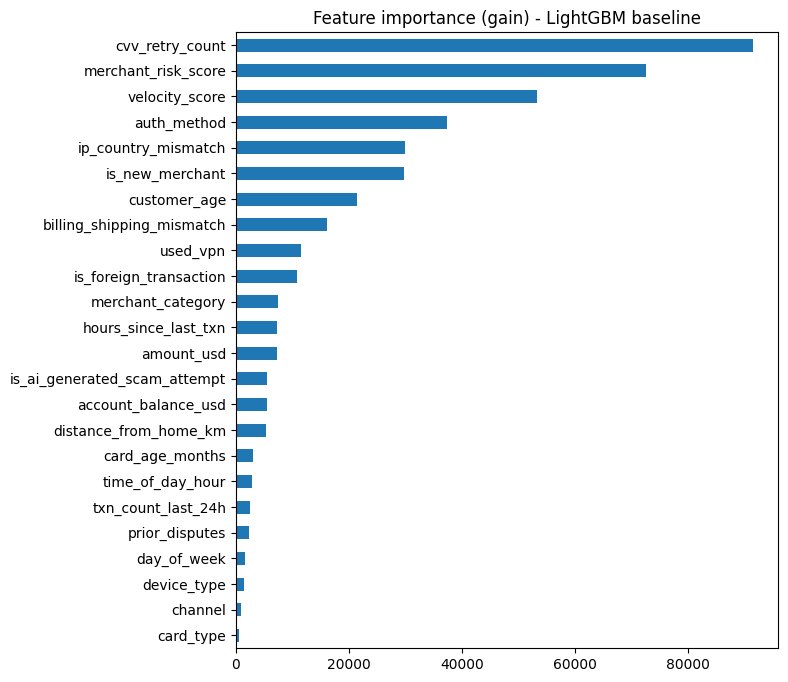

In [70]:
imp = pd.concat(importances, axis=1).mean(axis=1).sort_values()
imp.plot.barh(figsize=(7, 8), title='Feature importance (gain) - LightGBM baseline');

In [71]:
import shutil
shutil.copy(SUB_DIR / 'lgb_baseline.csv', SUB_DIR / 'baseline_submission.csv')
pd.read_csv(SUB_DIR / 'baseline_submission.csv').head()

,id,is_fraud
0,699960,0.000327
1,699961,0.000195
2,699962,0.081684
3,699963,0.001619
4,699964,0.001313


In [72]:
FILE_SUBMIT = SUB_DIR / 'baseline_submission.csv'
PESAN = f'lgb_baseline | CV {cv_lgb:.5f}'

SUBMIT_SEKARANG = False
if SUBMIT_SEKARANG:
    setup_kaggle()
    !kaggle competitions submit -c {COMP} -f "{FILE_SUBMIT}" -m "{PESAN}"
    !kaggle competitions submissions -c {COMP} | head -n 5
else:
    print('Belum submit. File:', FILE_SUBMIT)

Belum submit. File: ps-s6e11\submissions\baseline_submission.csv


In [73]:
def rank01(x):
    return (rankdata(x) - 1) / (len(x) - 1)


def load_models(names=None):
    if names is None:
        names = sorted(p.name[:-len('_oof.csv')] for p in OOF_DIR.glob('*_oof.csv'))
    O, T = {}, {}
    for n in names:
        o = train[[ID]].merge(pd.read_csv(OOF_DIR / f'{n}_oof.csv'), on=ID, how='left')
        t = sample[[ID]].merge(pd.read_csv(OOF_DIR / f'{n}_test.csv'), on=ID, how='left')
        assert o[TARGET].notna().all() and t[TARGET].notna().all(), f'{n}: id tidak lengkap'
        O[n], T[n] = rank01(o[TARGET].values), rank01(t[TARGET].values)
    return pd.DataFrame(O), pd.DataFrame(T)


def hill_climb(y, O, n_iter=50, tol=1e-6):
    names = list(O.columns)
    scores = {n: roc_auc_score(y, O[n]) for n in names}
    best = max(scores, key=scores.get)
    counts = dict.fromkeys(names, 0); counts[best] = 1
    blend, cur = O[best].values.copy(), scores[best]
    for i in range(1, n_iter):
        cand = {n: roc_auc_score(y, (blend * i + O[n].values) / (i + 1)) for n in names}
        nb = max(cand, key=cand.get)
        if cand[nb] - cur < tol:
            break
        blend = (blend * i + O[nb].values) / (i + 1)
        cur = cand[nb]; counts[nb] += 1
    total = sum(counts.values())
    return {n: c / total for n, c in counts.items() if c}, cur


def ensemble(names=None, out='ensemble'):
    y = train[TARGET].values
    O, T = load_models(names)
    print(f'{O.shape[1]} model:')
    for n in O.columns:
        print(f'  {n:<28} CV AUC {roc_auc_score(y, O[n]):.5f}')
    if O.shape[1] > 1:
        display(O.corr().round(3))

    eq_auc = roc_auc_score(y, O.mean(axis=1))
    w, hc_auc = hill_climb(y, O)
    hc_oof = sum(O[n] * v for n, v in w.items())
    fold_auc = [roc_auc_score(y[train.fold == k], hc_oof[train.fold == k]) for k in range(N_FOLDS)]
    print(f'\nRank-average CV AUC : {eq_auc:.5f}')
    print(f'Hill-climbing CV AUC: {hc_auc:.5f}  bobot={ {k: round(v, 3) for k, v in w.items()} }')
    print(f'Per-fold hill-climb : {np.round(fold_auc, 5)} (std {np.std(fold_auc):.5f})')

    for tag, p in [('rankavg', T.mean(axis=1)), ('hillclimb', sum(T[n] * v for n, v in w.items()))]:
        sub = sample[[ID]].copy(); sub[TARGET] = np.asarray(p)
        check_submission(sub)
        sub.to_csv(SUB_DIR / f'{out}_{tag}.csv', index=False)
        print('Tersimpan:', SUB_DIR / f'{out}_{tag}.csv')

ensemble()

1 model:
  lgb_baseline                 CV AUC 0.94632

Rank-average CV AUC : 0.94632
Hill-climbing CV AUC: 0.94632  bobot={'lgb_baseline': 1.0}
Per-fold hill-climb : [0.94459 0.94796 0.95091 0.94669 0.94174] (std 0.00309)
[OK] Format submission valid (299984 baris)
Tersimpan: ps-s6e11\submissions\ensemble_rankavg.csv
[OK] Format submission valid (299984 baris)
Tersimpan: ps-s6e11\submissions\ensemble_hillclimb.csv


In [74]:
pd.read_csv(ROOT / 'experiments.csv')

,waktu,nama,cv_auc,std_fold,public_lb
0,2026-11-03 21:35,lgb_baseline,0.946318,0.003092,NaN
1,2026-11-03 22:47,lgb_baseline,0.946318,0.003092,NaN
2,2026-11-03 23:11,lgb_baseline,0.946318,0.003092,NaN


# EDA, Data Hygiene & Preprocessing

## 1. Load, optimize memory, and audit

The loader downcasts numeric columns and converts low-cardinality text columns to `category`.



In [75]:
train, test, memory_report = eda.load_data(
    DATA_DIR / 'train.csv',
    DATA_DIR / 'test.csv',
)
print('train:', train.shape, 'test:', test.shape)
print(memory_report['train']['before_mb'], 'MB ->', memory_report['train']['after_mb'], 'MB')

audit = eda.basic_audit(train, test, target_col=TARGET, id_col=ID)
pd.Series(audit).to_frame('value')

NameError: name 'eda' is not defined

## 2. Target, outliers, and univariate signal

In [ ]:
features = [c for c in train.columns if c not in {TARGET, ID}]
numeric_features = [
    c for c in features
    if pd.api.types.is_numeric_dtype(train[c])
    and not pd.api.types.is_bool_dtype(train[c])
]
cat_features = [
    c for c in features
    if isinstance(train[c].dtype, pd.CategoricalDtype)
    or pd.api.types.is_object_dtype(train[c])
    or pd.api.types.is_string_dtype(train[c])
]
bool_features = [c for c in features if pd.api.types.is_bool_dtype(train[c])]

target_info = eda.target_summary(train, TARGET, ARTIFACT_DIR, show=True)
outliers = eda.outlier_report(train, numeric_features, ARTIFACT_DIR, show=True)
outliers.head(10)

In [ ]:
correlations = eda.correlation_report(
    train, TARGET, numeric_features, ARTIFACT_DIR, show=True
)
correlations.head(12)

In [ ]:
categorical = eda.categorical_report(
    train, cat_features, TARGET, ARTIFACT_DIR, show=True
)
booleans, risk_flags = eda.boolean_report(
    train, bool_features, TARGET, ARTIFACT_DIR, show=True
)
print('categorical rows:', len(categorical))
print('boolean rows:', len(booleans), 'risk rows:', len(risk_flags))
risk_flags

In [ ]:
eda.plot_feature_distributions(
    train,
    test,
    TARGET,
    correlations.head(6)['feature'].tolist(),
    ARTIFACT_DIR,
    show=True,
)

## 3. Adversarial validation

A small LightGBM model tries to distinguish train from test. AUC near 0.5 means the random split is safe.

In [ ]:
RUN_ADVERSARIAL = True

if RUN_ADVERSARIAL:
    adversarial = eda.adversarial_validation(
        train,
        test,
        target_col=TARGET,
        id_col=ID,
        outdir=ARTIFACT_DIR,
        max_per_side=150_000,
        n_splits=5,
        random_state=42,
        show=True,
    )
else:
    adversarial = {'status': 'skipped', 'reason': 'RUN_ADVERSARIAL=False'}

adversarial

## 4. Leakage-safe preprocessing

For LightGBM/CatBoost, use `categorical_mode='ordinal'` and pass the exposed categorical indices or names.

In [ ]:
y = train[TARGET].astype(np.int8)

prep = DataPreprocessor(
    target_col=TARGET,
    id_col=ID,
    categorical_mode='ordinal',
    scale_numeric=False,
    random_state=42,
)
X_train = prep.fit_transform(train, y)
X_test = prep.transform(test)

print('X_train:', X_train.shape, 'X_test:', X_test.shape)
print('columns match:', list(X_train.columns) == list(X_test.columns))
print('NaNs:', int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum()))
print('categorical names:', prep.get_cat_feature_names())
print('categorical indices:', prep.get_cat_feature_indices())
X_train.head()

In [ ]:
prep.summary()

## 5. Key findings

This is the same `KEY_FINDINGS.md` produced by `run_stage1.py`.

In [ ]:
markdown = eda.build_key_findings(
    audit=audit,
    target=target_info,
    outliers=outliers,
    correlations=correlations,
    categorical=categorical,
    booleans=booleans,
    risk_flags=risk_flags,
    adversarial=adversarial,
    preprocessor_summaries={'ordinal': prep.summary()},
    outdir=ARTIFACT_DIR,
)
path = eda.save_key_findings(markdown, ARTIFACT_DIR)
print('saved:', path)
display(Markdown(markdown))